# Predicting life expectancy from health, immunization and socioeconomic factors

This notebook uses the WHO Life Expectancy dataset to build and evaluate a linear regression model. The four parts follow the project roles: data exploration and cleaning, model building, evaluation, and result plots.


In [1]:
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Data").is_dir())
DATA_PATH = ROOT / "Data" / "Life Expectancy Data.csv"


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


## Part 1: Data exploration, pre-processing charts and cleaning (Execution lead)

The first function reads the CSV and cleans the column names. The raw file has extra spaces at the ends of names and double spaces inside some names, so both are fixed before any analysis. We then call it on the dataset path and define the target column once.


In [3]:
def load_and_clean(path):
    """Read the CSV and clean the column names."""
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip().str.replace(r"\s+", " ", regex=True)
    return df


In [4]:
TARGET = "Life expectancy"

df = load_and_clean(DATA_PATH)
assert TARGET in df.columns # assert is a Python keyword used for debugging. It tests a condition, and if the condition is False, it raises an AssertionError.

print("Shape:", df.shape)


Shape: (2938, 22)


Next we inspect the data: its size, the first rows, column types, summary statistics, and how many values are missing in each column.

In [5]:
df.head()


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   str    
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   str    
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10  BMI                              2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio                          

In [7]:
df.describe()

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
count,2938.000000,2928.000000,2928.000000,2938.000000,2744.000000,2938.000000,2385.000000,2938.000000,2904.000000,2938.000000,2919.000000,2712.00000,2919.000000,2938.000000,2490.000000,2.286000e+03,2904.000000,2904.000000,2771.000000,2775.000000
mean,2007.518720,69.224932,164.796448,30.303948,4.602861,738.251295,80.940461,2419.592240,38.321247,42.035739,82.550188,5.93819,82.324084,1.742103,7483.158469,1.275338e+07,4.839704,4.870317,0.627551,11.992793
std,4.613841,9.523867,124.292079,117.926501,4.052413,1987.914858,25.070016,11467.272489,20.044034,160.445548,23.428046,2.49832,23.716912,5.077785,14270.169342,6.101210e+07,4.420195,4.508882,0.210904,3.358920
min,2000.000000,36.300000,1.000000,0.000000,0.010000,0.000000,1.000000,0.000000,1.000000,0.000000,3.000000,0.37000,2.000000,0.100000,1.681350,3.400000e+01,0.100000,0.100000,0.000000,0.000000
25%,2004.000000,63.100000,74.000000,0.000000,0.877500,4.685343,77.000000,0.000000,19.300000,0.000000,78.000000,4.26000,78.000000,0.100000,463.935626,1.957932e+05,1.600000,1.500000,0.493000,10.100000
50%,2008.000000,72.100000,144.000000,3.000000,3.755000,64.912906,92.000000,17.000000,43.500000,4.000000,93.000000,5.75500,93.000000,0.100000,1766.947595,1.386542e+06,3.300000,3.300000,0.677000,12.300000
75%,2012.000000,75.700000,228.000000,22.000000,7.702500,441.534144,97.000000,360.250000,56.200000,28.000000,97.000000,7.49250,97.000000,0.800000,5910.806335,7.420359e+06,7.200000,7.200000,0.779000,14.300000
max,2015.000000,89.000000,723.000000,1800.000000,17.870000,19479.911610,99.000000,212183.000000,87.300000,2500.000000,99.000000,17.60000,99.000000,50.600000,119172.741800,1.293859e+09,27.700000,28.600000,0.948000,20.700000


In [8]:
df.isna().sum()


Country                              0
Year                                 0
Status                               0
Life expectancy                     10
Adult Mortality                     10
infant deaths                        0
Alcohol                            194
percentage expenditure               0
Hepatitis B                        553
Measles                              0
BMI                                 34
under-five deaths                    0
Polio                               19
Total expenditure                  226
Diphtheria                          19
HIV/AIDS                             0
GDP                                448
Population                         652
thinness 1-19 years                 34
thinness 5-9 years                  34
Income composition of resources    167
Schooling                          163
dtype: int64

The `plot_eda` function draws the charts we need before dropping anything. It shows the target distribution, missing values, correlations between numeric columns, and how three important features relate to life expectancy.

In [9]:
def plot_eda(df):
    """Draw the main exploratory charts for the dataset."""
    plt.figure(figsize=(8, 5))
    plt.hist(df[TARGET].dropna(), bins=30)
    plt.title("Distribution of life expectancy")
    plt.xlabel("Life expectancy (years)")
    plt.ylabel("Number of rows")
    plt.tight_layout()
    plt.show()

    missing = df.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    plt.figure(figsize=(10, 6))
    missing.plot(kind="bar")
    plt.title("Missing values per column")
    plt.xlabel("Column")
    plt.ylabel("Number of missing values")
    plt.tight_layout()
    plt.show()

    correlation = df.corr(numeric_only=True)
    plt.figure(figsize=(16, 12))
    sns.heatmap(correlation, cmap="coolwarm", center=0)
    plt.title("Correlation heatmap of numeric columns")
    plt.xlabel("Column")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()

    scatter_columns = ["Schooling", "Income composition of resources", "Adult Mortality"]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, column in zip(axes, scatter_columns):
        ax.scatter(df[column], df[TARGET], alpha=0.4, s=10)
        ax.set_title(f"{column} vs life expectancy")
        ax.set_xlabel(column)
        ax.set_ylabel("Life expectancy (years)")
    plt.tight_layout()
    plt.show()


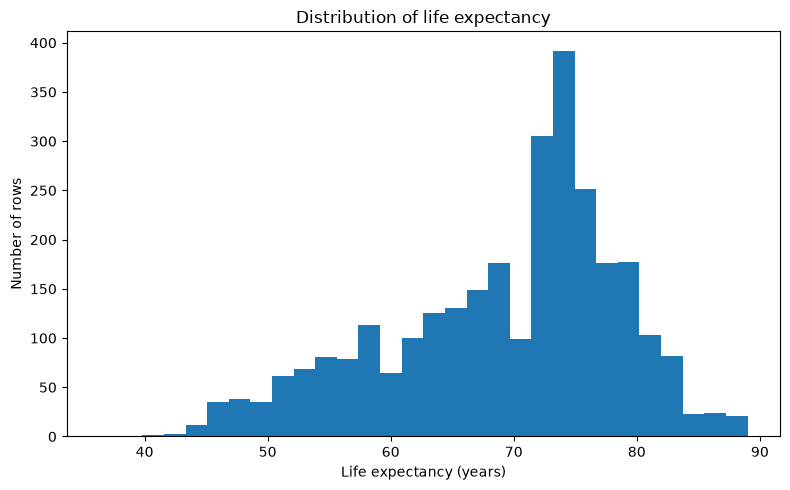

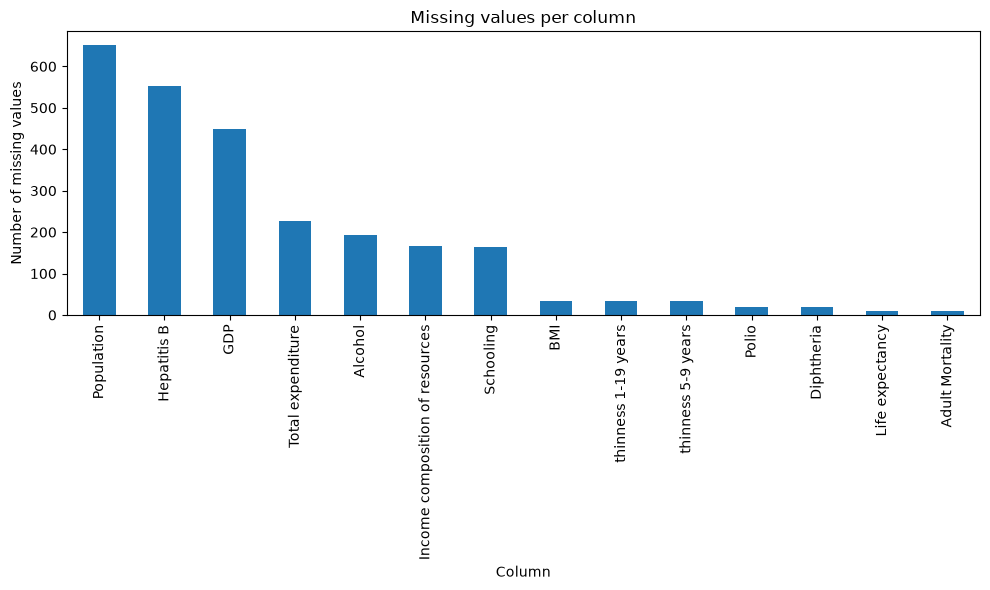

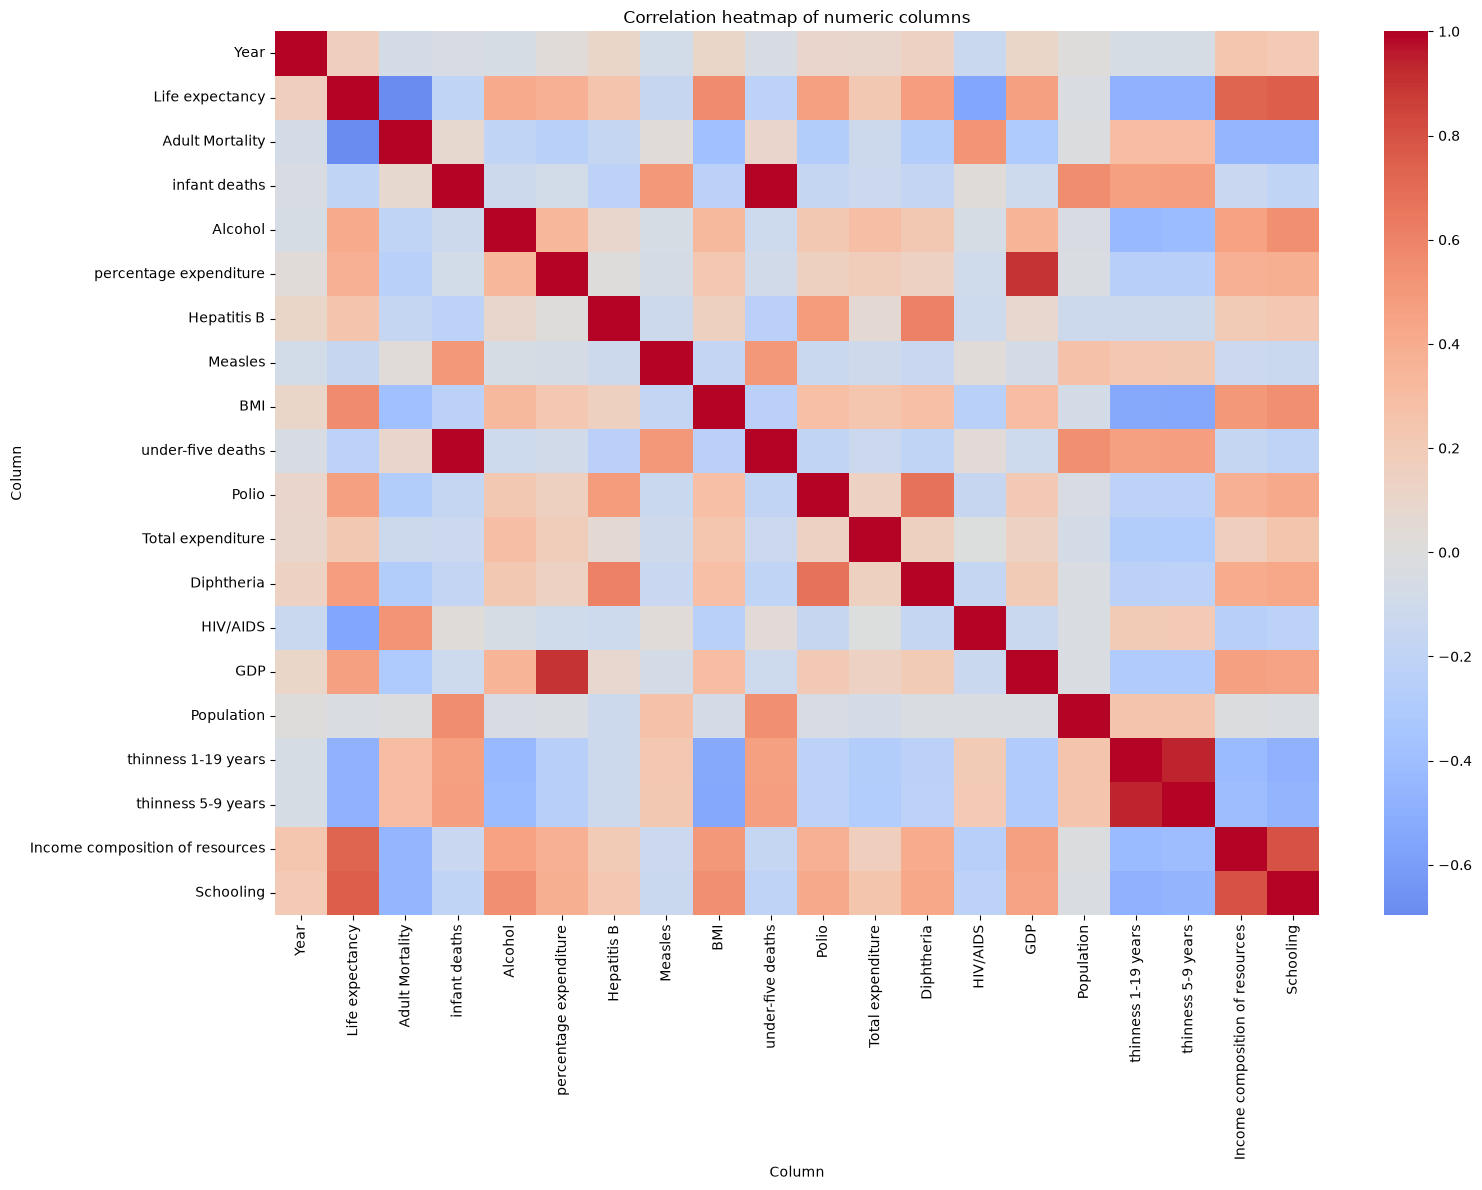

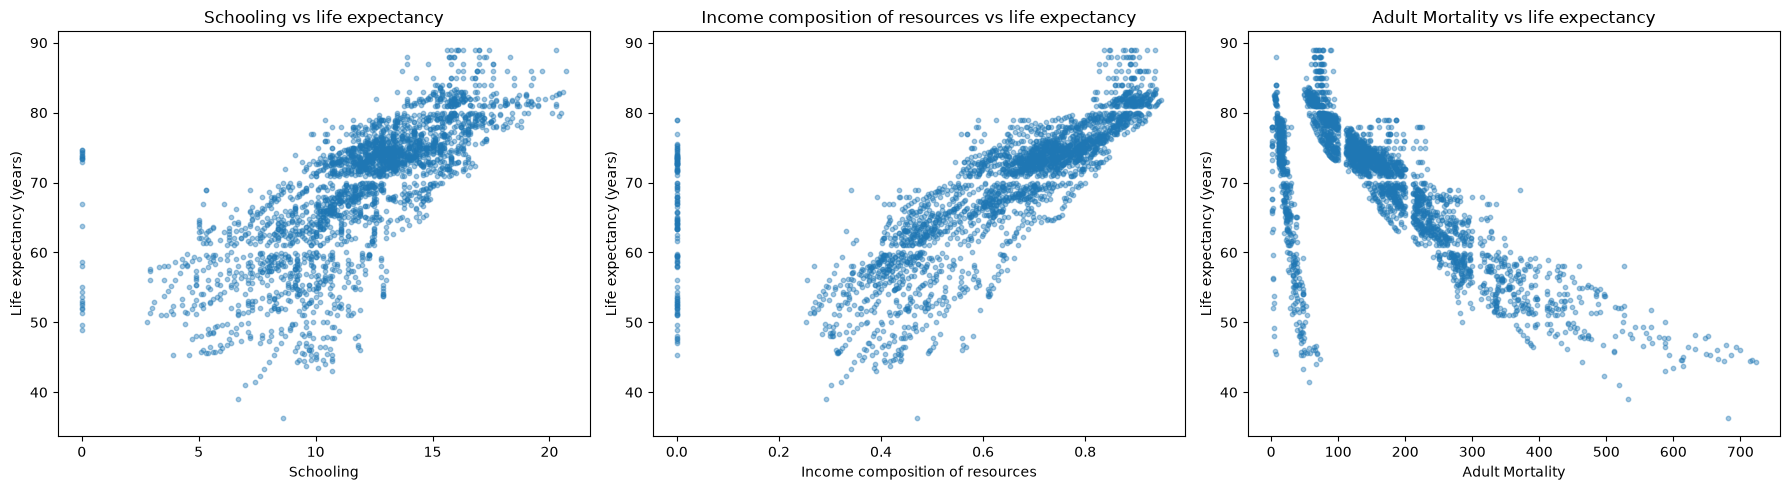

In [10]:
plot_eda(df)


We now remove columns and rows that would hurt the model or cannot be used. The reasons are kept in a dictionary so they can be printed and checked.

The redundant columns are kept in one list.

In [11]:
REDUNDANT_COLUMNS = ["infant deaths", "thinness 5-9 years", "percentage expenditure"]


`Country` is an identifier, rows without the target cannot be used, and the redundant columns duplicate information already in the dataset. The dictionary records one reason for each drop.

In [12]:
DROP_REASONS = {
    "Country": "Identifier with about 193 unique values; one-hot encoding it would add hundreds of columns.",
    "Rows with missing Life expectancy": "The target cannot be imputed, so these rows are removed.",
    "infant deaths": "Almost the same information as under-five deaths.",
    "thinness 5-9 years": "Almost the same information as thinness 1-19 years.",
    "percentage expenditure": "Almost the same information as GDP."
}

df = df.drop(columns=["Country"] + REDUNDANT_COLUMNS)
df = df.dropna(subset=[TARGET]).reset_index(drop=True)

print("Dropped columns and rows:")
for name, reason in DROP_REASONS.items():
    print(f"- {name}: {reason}")
print("Shape after drops:", df.shape)


Dropped columns and rows:
- Country: Identifier with about 193 unique values; one-hot encoding it would add hundreds of columns.
- Rows with missing Life expectancy: The target cannot be imputed, so these rows are removed.
- infant deaths: Almost the same information as under-five deaths.
- thinness 5-9 years: Almost the same information as thinness 1-19 years.
- percentage expenditure: Almost the same information as GDP.
Shape after drops: (2928, 18)


The cleaned dataframe is split into features `X` and target `y`. `Country` is already gone, and `TARGET` is the life expectancy column.

In [13]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (2928, 17)
y shape: (2928,)


This part hands over `df`, `X` and `y`.